# Лабораторна робота №3

**Мета:** Ознайомитися з базовим workflow побудови та навчання нейронних мереж для різних типів даних: табличних даних, зображень і текстів; дослідити процес навчання моделей та порівняти нейромережеві підходи з класичними алгоритмами машинного навчання.

## 1. Повнозв’язна нейронна мережа (MLP)


### 1.1. Імпорт бібліотек і параметри

In [103]:
from pathlib import Path
import random
import gzip
import re
from collections import Counter
from time import perf_counter

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from PIL import Image
from torchvision import models, transforms

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 69
BATCH_SIZE = 128
EPOCHS = 20
LEARNING_RATE = 0.001

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)


DATA_PATH = next(
    path for path in [Path("data/PhiUSIIL_Phishing_URL_Dataset.csv"),
                      Path("../data/PhiUSIIL_Phishing_URL_Dataset.csv")]
    if path.exists()
)


device: mps


### 1.2. Завантаження датасету й ознак

Беремо 20 ознак URL, які використовувалися в лабораторній роботі №1. Ознака `TLD` є категоріальною, решта ознак — числові.

In [90]:
data = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
data = data.drop_duplicates(subset="URL")

features = [
    "URLLength", "TLD", "DomainLength", "IsDomainIP", "TLDLength",
    "NoOfSubDomain", "CharContinuationRate", "HasObfuscation",
    "NoOfObfuscatedChar", "ObfuscationRatio", "NoOfLettersInURL",
    "LetterRatioInURL", "NoOfDegitsInURL", "DegitRatioInURL",
    "NoOfEqualsInURL", "NoOfQMarkInURL", "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL", "SpacialCharRatioInURL", "IsHTTPS",
]

sample, _ = train_test_split(
    data, train_size=10_000, stratify=data["label"], random_state=RANDOM_STATE
)

print("Розподіл класів (0 — фішинг, 1 — легітимний):")
display(sample["label"].value_counts().sort_index().rename("Кількість").to_frame())


Розподіл класів (0 — фішинг, 1 — легітимний):


,Кількість
label,
0,4271
1,5729


### 1.3. Поділ на train, validation і test

Тестову вибірку залишаємо для фінального оцінювання. Validation потрібна, щоб порівняти варіанти моделі під час навчання. Масштабування й кодування налаштовуємо лише на train-частині — це запобігає витоку інформації.

In [91]:
development, test = train_test_split(
    sample, test_size=0.20, stratify=sample["label"], random_state=RANDOM_STATE
)
train, validation = train_test_split(
    development, test_size=0.20, stratify=development["label"], random_state=RANDOM_STATE
)

numeric_features = [name for name in features if name != "TLD"]
preprocessor = ColumnTransformer([
    ("numbers", StandardScaler(), numeric_features),
    ("tld", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["TLD"]),
])

X_train = preprocessor.fit_transform(train[features]).astype("float32")
X_validation = preprocessor.transform(validation[features]).astype("float32")
X_test = preprocessor.transform(test[features]).astype("float32")
y_train = train["label"].to_numpy(dtype="int64")
y_validation = validation["label"].to_numpy(dtype="int64")
y_test = test["label"].to_numpy(dtype="int64")

print(f"Train: {len(train):,} | Validation: {len(validation):,} | Test: {len(test):,}")
print(f"Кількість числових входів після кодування TLD: {X_train.shape[1]}")


Train: 6,400 | Validation: 1,600 | Test: 2,000
Кількість числових входів після кодування TLD: 239


### 1.4. Архітектура MLP і навчання

Мережа має один прихований повнозв’язаний шар. Розмір прихованого шару перевіримо окремо. Для кожного варіанта зберігаємо модель з найменшою validation loss.

In [92]:
train_data = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
validation_data = TensorDataset(torch.from_numpy(X_validation), torch.from_numpy(y_validation))
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
validation_loader = DataLoader(validation_data, batch_size=BATCH_SIZE)


def train_mlp(hidden_size):
    model = nn.Sequential(
        nn.Linear(X_train.shape[1], hidden_size),
        nn.ReLU(),
        nn.Linear(hidden_size, 2),
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_function = nn.CrossEntropyLoss()
    history = {"train_loss": [], "validation_loss": [], "validation_macro_f1": []}
    best_loss = float("inf")
    best_weights = None

    for epoch in range(EPOCHS):
        model.train()
        train_loss_sum = 0.0
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            optimizer.zero_grad()
            loss = loss_function(model(batch_X), batch_y)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(batch_y)

        model.eval()
        validation_loss_sum = 0.0
        validation_true, validation_pred = [], []
        with torch.no_grad():
            for batch_X, batch_y in validation_loader:
                batch_X, batch_y = batch_X.to(device), batch_y.to(device)
                scores = model(batch_X)
                validation_loss_sum += loss_function(scores, batch_y).item() * len(batch_y)
                validation_true.extend(batch_y.cpu().numpy())
                validation_pred.extend(scores.argmax(dim=1).cpu().numpy())

        train_loss = train_loss_sum / len(train_data)
        validation_loss = validation_loss_sum / len(validation_data)
        validation_f1 = f1_score(validation_true, validation_pred, average="macro")
        history["train_loss"].append(train_loss)
        history["validation_loss"].append(validation_loss)
        history["validation_macro_f1"].append(validation_f1)

        if validation_loss < best_loss:
            best_loss = validation_loss
            best_weights = {name: value.clone() for name, value in model.state_dict().items()}

    model.load_state_dict(best_weights)
    return model, history


### 1.5. Вплив розміру прихованого шару

Порівняємо 32, 64 і 128 нейронів у прихованому шарі за однакових умов навчання. Результат оцінюємо на validation за Macro F1; тестова вибірка в цьому виборі не бере участі.

In [93]:
hidden_sizes = [16, 32, 64, 128]
models = {}
histories = {}
validation_scores = []

for hidden_size in hidden_sizes:
    # Однаковий початковий стан робить порівняння відтворюваним.
    torch.manual_seed(RANDOM_STATE)
    model, history = train_mlp(hidden_size)
    models[hidden_size] = model
    histories[hidden_size] = history
    best_epoch = int(np.argmin(history["validation_loss"]))
    validation_scores.append(history["validation_macro_f1"][best_epoch])

best_hidden_size = hidden_sizes[int(np.argmax(validation_scores))]
print(f"Обраний розмір прихованого шару: {best_hidden_size}")


Обраний розмір прихованого шару: 32


In [94]:
parameter_results = pd.DataFrame({
    "Нейронів у прихованому шарі": hidden_sizes,
    "Validation Macro F1": validation_scores
})
display(parameter_results.round(5))

,Нейронів у прихованому шарі,Validation Macro F1
0,16,0.99680
1,32,0.99744
2,64,0.99744
3,128,0.99744


### 1.6. Learning curves обраної моделі

Графік показує train loss і validation loss за епохами. Якщо train loss продовжує знижуватися, а validation loss зростає, це може вказувати на перенавчання.

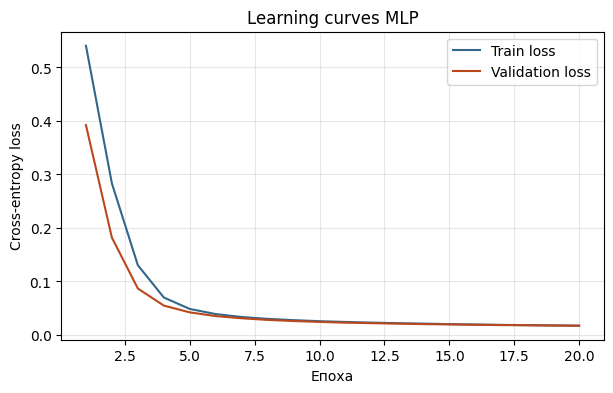

In [95]:
history = histories[best_hidden_size]
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(7, 4))
plt.plot(epochs, history["train_loss"], label="Train loss", color="#326789")
plt.plot(epochs, history["validation_loss"], label="Validation loss", color="#bb471d")
plt.xlabel("Епоха")
plt.ylabel("Cross-entropy loss")
plt.title("Learning curves MLP")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


### 1.7. Оцінювання на test

Застосовуємо обрану за validation модель до тестової вибірки. Окрім Accuracy, дивимося на Precision, Recall і F1 для кожного класу.

Accuracy: 0.9975
Macro F1: 0.9974
                    precision    recall  f1-score   support

        Фішинг (0)     0.9988    0.9953    0.9971       854
Легітимний URL (1)     0.9965    0.9991    0.9978      1146

          accuracy                         0.9975      2000
         macro avg     0.9977    0.9972    0.9974      2000
      weighted avg     0.9975    0.9975    0.9975      2000



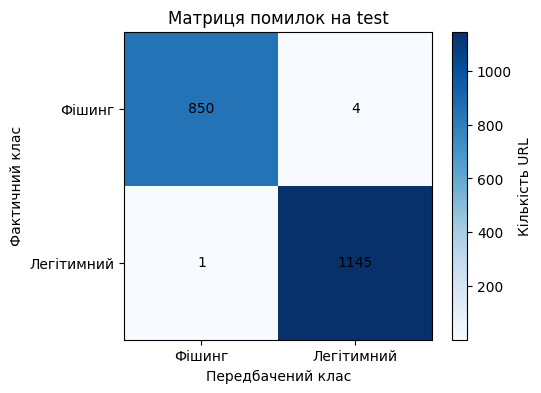

In [96]:
best_model = models[best_hidden_size]
best_model.eval()
with torch.no_grad():
    test_scores = best_model(torch.from_numpy(X_test).to(device))
    test_predictions = test_scores.argmax(dim=1).cpu().numpy()

print(f"Accuracy: {accuracy_score(y_test, test_predictions):.4f}")
print(f"Macro F1: {f1_score(y_test, test_predictions, average='macro'):.4f}")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Фішинг (0)", "Легітимний URL (1)"],
    digits=4,
))

matrix = confusion_matrix(y_test, test_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(matrix, cmap="Blues")
ax.set(
    title="Матриця помилок на test",
    xlabel="Передбачений клас",
    ylabel="Фактичний клас",
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["Фішинг", "Легітимний"],
    yticklabels=["Фішинг", "Легітимний"],
)
for row in range(2):
    for column in range(2):
        ax.text(column, row, matrix[row, column], ha="center", va="center")
fig.colorbar(image, ax=ax, label="Кількість URL")
plt.show()


## 2. Згорткові нейронні мережі

Порівняємо CNN, навчену з нуля, та MobileNetV3 з попередньо навченими вагами.

### 2.1. Обраний датасет

У [Butterfly Image Classification](https://www.kaggle.com/datasets/phucthaiv02/butterfly-image-classification)  6 499 зображень і 75 видів метеликів.

Зображень: 6,499
Класів: 75
Кількість зображень у кожному класі:


,Зображень
label,
ADONIS,88
AFRICAN GIANT SWALLOWTAIL,75
AMERICAN SNOOT,74
AN 88,85
APPOLLO,90
...,...
ULYSES,84
VICEROY,81
WOOD SATYR,71


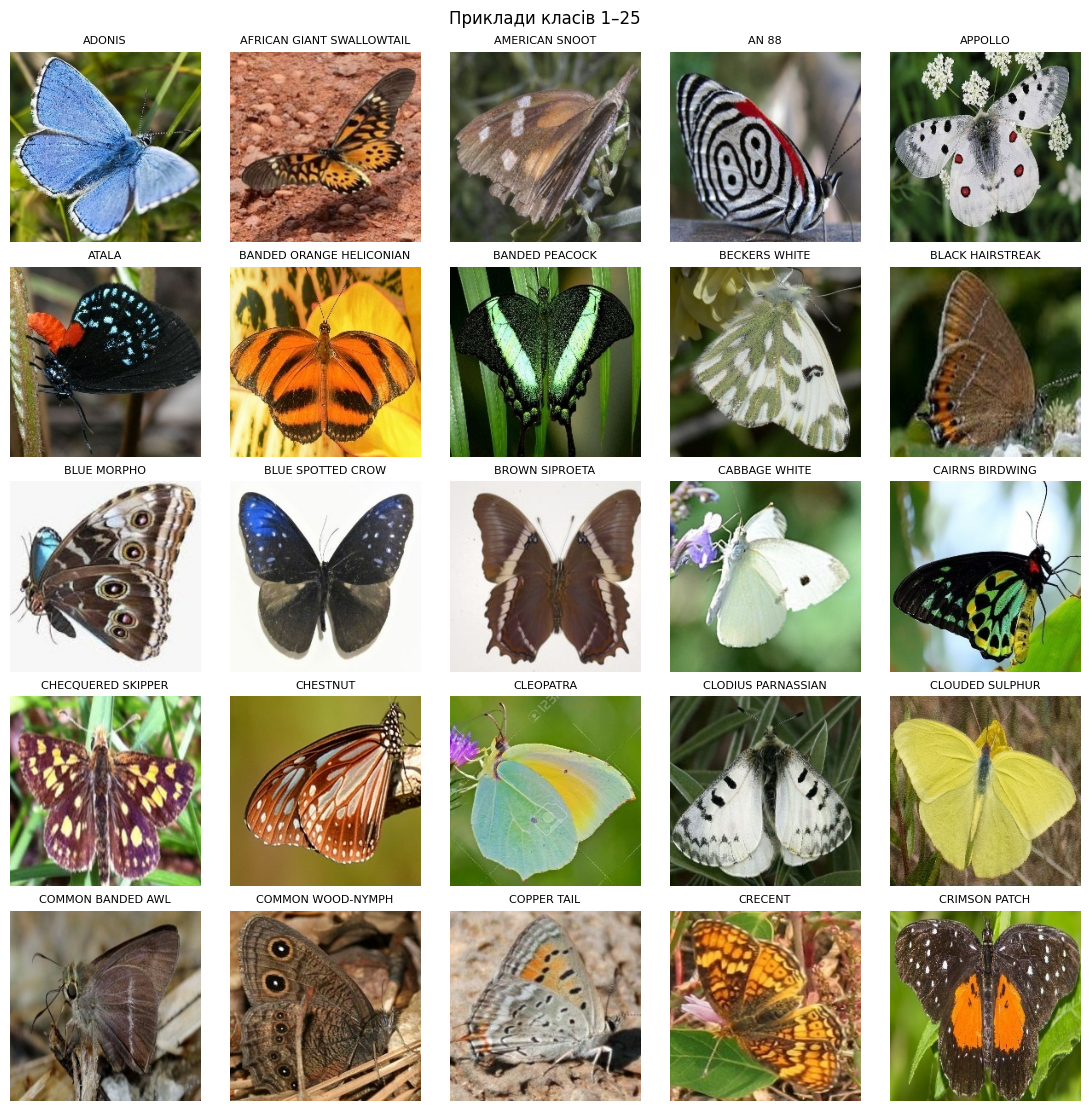

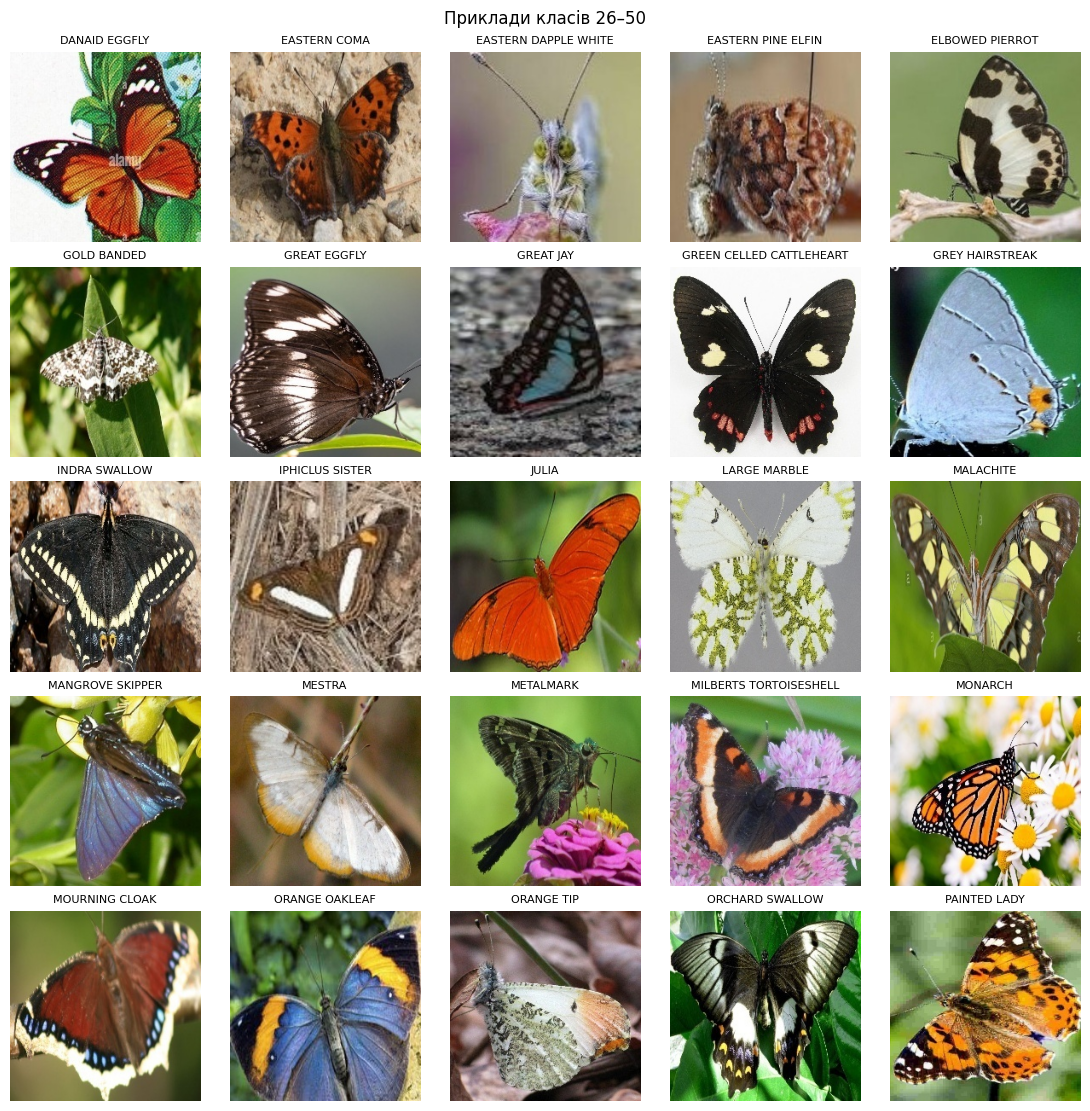

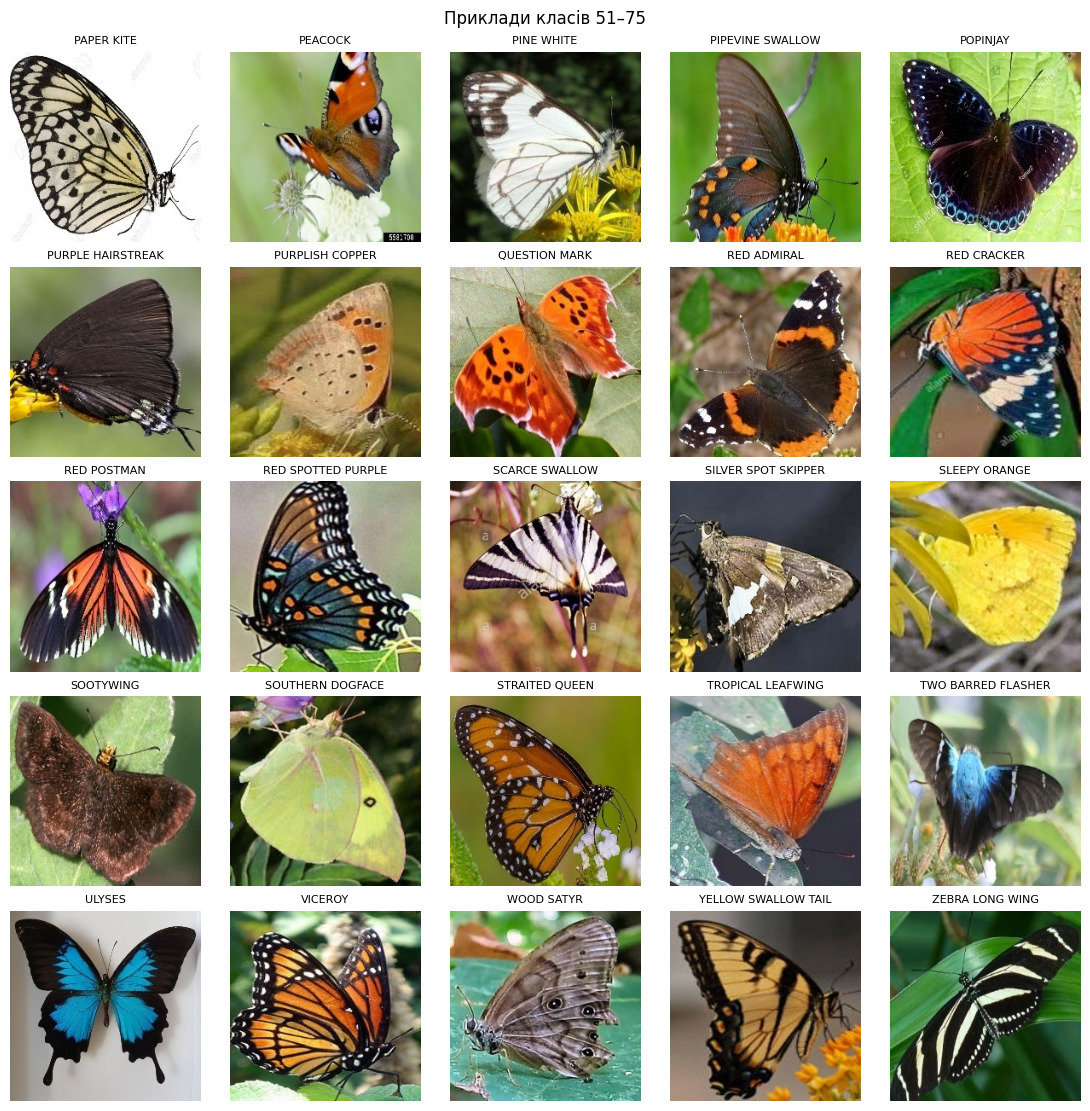

In [97]:
IMG_DIR = DATA_PATH.parent / "img"
image_df = pd.read_csv(IMG_DIR / "Training_set.csv")
image_classes = sorted(image_df["label"].unique())
class_to_id = {name: index for index, name in enumerate(image_classes)}
image_df["target"] = image_df["label"].map(class_to_id)

print(f"Зображень: {len(image_df):,}")
print(f"Класів: {len(image_classes)}")
print("Кількість зображень у кожному класі:")
display(image_df["label"].value_counts().sort_index().rename("Зображень").to_frame())

for page in range(3):
    page_classes = image_classes[page * 25:(page + 1) * 25]
    fig, axes = plt.subplots(5, 5, figsize=(11, 11), layout="constrained")
    for name, ax in zip(page_classes, axes.flat):
        filename = image_df.loc[image_df["label"] == name, "filename"].iloc[0]
        with Image.open(IMG_DIR / "train" / filename) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(name, fontsize=8)
        ax.axis("off")
    fig.suptitle(f"Приклади класів {page * 25 + 1}–{page * 25 + len(page_classes)}")
    plt.show()


### 2.2. Поділ даних і підготовка зображень

Ділимо підписані зображення на train, validation і test у пропорції 70/15/15 зі збереженням часток класів. Усі зображення приводимо до 92×92 пікселів і нормалізуємо однаково для обох моделей.

In [98]:
image_train, image_holdout = train_test_split(
    image_df, test_size=0.30, stratify=image_df["target"], random_state=RANDOM_STATE
)
image_validation, image_test = train_test_split(
    image_holdout, test_size=0.50, stratify=image_holdout["target"], random_state=RANDOM_STATE
)

to_tensor = transforms.Compose([
    transforms.Resize((92, 92)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class ButterflyDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(IMG_DIR / "train" / row["filename"]) as image:
            image = to_tensor(image.convert("RGB"))
        return image, int(row["target"])

train_dataset = ButterflyDataset(image_train)
validation_dataset = ButterflyDataset(image_validation)
test_dataset = ButterflyDataset(image_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=0)
validation_loader = DataLoader(validation_dataset, batch_size=64, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=64, num_workers=0)

display(pd.DataFrame({
    "Вибірка": ["Train", "Validation", "Test"],
    "Зображень": [len(train_dataset), len(validation_dataset), len(test_dataset)],
}))


,Вибірка,Зображень
0,Train,4549
1,Validation,975
2,Test,975


### 2.3.  CNN навчена з нуля

Мережа містить три згорткові шари з ReLU та зменшенням розмірності, після яких іде повнозв’язаний класифікатор на 75 класів. 
На кожній епосі рахуємо loss на train і validation та  подальшого оцінювання зберігаємо ваги з найменшою validation loss.

In [99]:
class SimpleCNN(nn.Module):
    def __init__(self, number_of_classes):
        super().__init__()

        self.convolutions = nn.Sequential(
            # Блок 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            # Блок 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            # Блок 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            # Блок 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(256, number_of_classes)
        )

    def forward(self, images):
        features = self.convolutions(images)
        return self.classifier(features)

def train_model(model, train_data, validation_data, epochs, learning_rate):
    model = model.to(device)

    optimizer = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad),
        lr=learning_rate,
        weight_decay=1e-4
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=4
    )

    loss_function = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "validation_loss": [],
        "seconds": []
    }

    best_loss = float("inf")
    best_weights = None

    patience = 12
    no_improvement = 0

    for epoch in range(epochs):
        start = perf_counter()

        model.train()
        train_loss_sum = 0.0

        for images, labels in train_data:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = loss_function(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * len(labels)

        model.eval()
        validation_loss_sum = 0.0

        with torch.no_grad():
            for images, labels in validation_data:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = loss_function(outputs, labels)

                validation_loss_sum += loss.item() * len(labels)

        train_loss = train_loss_sum / len(train_data.dataset)
        validation_loss = validation_loss_sum / len(validation_data.dataset)

        history["train_loss"].append(train_loss)
        history["validation_loss"].append(validation_loss)
        history["seconds"].append(perf_counter() - start)

        scheduler.step(validation_loss)

        print(
            f"Epoch {epoch + 1}/{epochs}: "
            f"train loss={train_loss:.4f}, "
            f"validation loss={validation_loss:.4f}"
        )

        if validation_loss < best_loss - 1e-4:
            best_loss = validation_loss
            best_weights = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }
            no_improvement = 0
        else:
            no_improvement += 1

        if no_improvement >= patience:
            print(f"Early stopping  epoch: {epoch + 1}")
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)

    return model, history


def predict(model, loader):
    model.eval()
    true_labels, predictions = [], []
    with torch.no_grad():
        for images, labels in loader:
            scores = model(images.to(device))
            predictions.extend(scores.argmax(dim=1).cpu().numpy())
            true_labels.extend(labels.numpy())
    return np.array(true_labels), np.array(predictions)


In [100]:
CNN_EPOCHS = 65
cnn = SimpleCNN(len(image_classes))
cnn, cnn_history = train_model(
    cnn, train_loader, validation_loader, epochs=CNN_EPOCHS, learning_rate=0.001
)


Epoch 1/65: train loss=3.9787, validation loss=3.5025
Epoch 2/65: train loss=3.4534, validation loss=3.1181
Epoch 3/65: train loss=3.1578, validation loss=2.8580
Epoch 4/65: train loss=2.9278, validation loss=2.6778
Epoch 5/65: train loss=2.7752, validation loss=2.5038
Epoch 6/65: train loss=2.6516, validation loss=2.3574
Epoch 7/65: train loss=2.5398, validation loss=2.3623
Epoch 8/65: train loss=2.4451, validation loss=2.2491
Epoch 9/65: train loss=2.3179, validation loss=2.0688
Epoch 10/65: train loss=2.2648, validation loss=1.9747
Epoch 11/65: train loss=2.2135, validation loss=1.9413
Epoch 12/65: train loss=2.1387, validation loss=1.8700
Epoch 13/65: train loss=2.0583, validation loss=1.7763
Epoch 14/65: train loss=2.0014, validation loss=1.8188
Epoch 15/65: train loss=1.9355, validation loss=1.7484
Epoch 16/65: train loss=1.8944, validation loss=1.6116
Epoch 17/65: train loss=1.8297, validation loss=1.5409
Epoch 18/65: train loss=1.8021, validation loss=1.5295
Epoch 19/65: train 

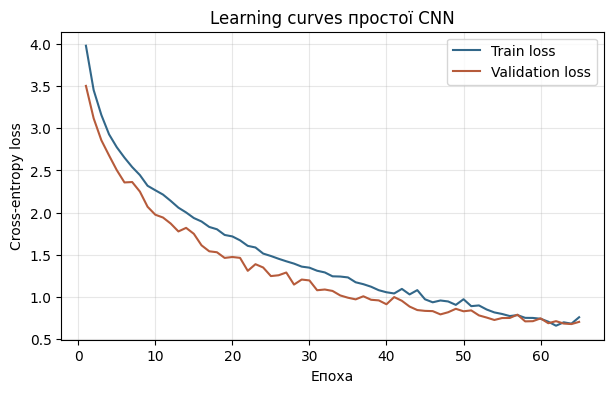

In [101]:
epochs = range(1, CNN_EPOCHS + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, cnn_history["train_loss"], label="Train loss", color="#326789")
plt.plot(epochs, cnn_history["validation_loss"], label="Validation loss", color="#b65b3b")
plt.xlabel("Епоха")
plt.ylabel("Cross-entropy loss")
plt.title("Learning curves простої CNN")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


### 2.4. MobileNetV3 з попередньо навченими вагами

Використовуємо  ваги MobileNetV3 Small. Замінюємо останній шар класифікатора на 75 виходів. 

In [104]:
PRETRAINED_PATH = DATA_PATH.parent / "pretrained" / "mobilenet_v3_small-047dcff4.pth"
mobile_net = models.mobilenet_v3_small(weights=None)
mobile_net.load_state_dict(torch.load(PRETRAINED_PATH, map_location="cpu", weights_only=True))

for parameter in mobile_net.features.parameters():
    parameter.requires_grad = False
for parameter in mobile_net.features[-1].parameters():
    parameter.requires_grad = True

number_of_features = mobile_net.classifier[-1].in_features
mobile_net.classifier[-1] = nn.Linear(number_of_features, len(image_classes))

MOBILENET_EPOCHS = 12
mobile_net, mobile_history = train_model(
    mobile_net, train_loader, validation_loader,
    epochs=MOBILENET_EPOCHS, learning_rate=0.0001,
)


Epoch 1/12: train loss=4.2164, validation loss=3.9571
Epoch 2/12: train loss=3.6883, validation loss=3.4492
Epoch 3/12: train loss=3.1541, validation loss=2.9983
Epoch 4/12: train loss=2.6610, validation loss=2.6424
Epoch 5/12: train loss=2.2531, validation loss=2.3963
Epoch 6/12: train loss=1.9500, validation loss=2.2261
Epoch 7/12: train loss=1.7467, validation loss=2.1115
Epoch 8/12: train loss=1.5736, validation loss=2.0184
Epoch 9/12: train loss=1.4615, validation loss=1.9515
Epoch 10/12: train loss=1.3577, validation loss=1.9023
Epoch 11/12: train loss=1.2573, validation loss=1.8566
Epoch 12/12: train loss=1.1857, validation loss=1.8158


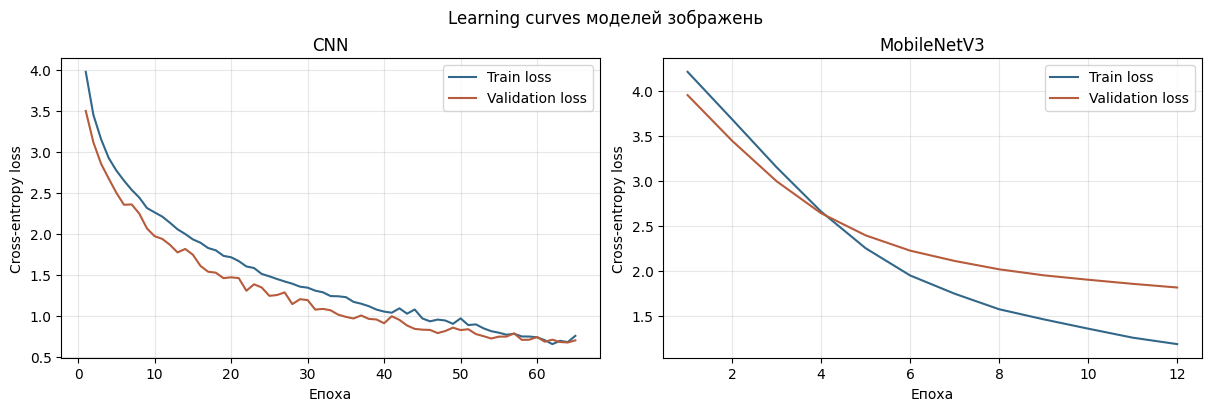

In [105]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, name, history in [
    (axes[0], "CNN", cnn_history),
    (axes[1], "MobileNetV3", mobile_history),
]:
    epochs = range(1, len(history["train_loss"]) + 1)
    ax.plot(epochs, history["train_loss"], label="Train loss", color="#326789")
    ax.plot(epochs, history["validation_loss"], label="Validation loss", color="#b65b3b")
    ax.set(title=name, xlabel="Епоха", ylabel="Cross-entropy loss")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Learning curves моделей зображень")
plt.show()


### 2.5. Порівняння якості та швидкості збіжності

Оцінюємо обидві моделі на одній тестовій вибірці. Macro F1 враховує якість для кожного виду, а середній час епохи допомагає порівняти швидкість навчання.

In [106]:
cnn_true, cnn_predictions = predict(cnn, test_loader)
mobile_true, mobile_predictions = predict(mobile_net, test_loader)

image_results = pd.DataFrame([
    {
        "Модель": "CNN з нуля",
        "Accuracy": accuracy_score(cnn_true, cnn_predictions),
        "Macro F1": f1_score(cnn_true, cnn_predictions, average="macro"),
        "Найкраща епоха": int(np.argmin(cnn_history["validation_loss"])) + 1,
        "Секунд на епоху": np.mean(cnn_history["seconds"]),
        "Час навчання, с": sum(cnn_history["seconds"]),
    },
    {
        "Модель": "MobileNetV3",
        "Accuracy": accuracy_score(mobile_true, mobile_predictions),
        "Macro F1": f1_score(mobile_true, mobile_predictions, average="macro"),
        "Найкраща епоха": int(np.argmin(mobile_history["validation_loss"])) + 1,
        "Секунд на епоху": np.mean(mobile_history["seconds"]),
        "Час навчання, с": sum(mobile_history["seconds"]),
    },
])
display(image_results.round(4))


,Модель,Accuracy,Macro F1,Найкраща епоха,Секунд на епоху,"Час навчання, с"
0,CNN з нуля,0.7959,0.7948,64,22.7776,1480.5433
1,MobileNetV3,0.5569,0.5502,12,9.8419,118.1023


### 2.6. Вплив кількості тренувальних зображень

Порівняємо повний train-набір із чвертю прикладів. Validation і test залишаємо незмінними. Це показує, як обсяг навчальних даних впливає на Macro F1 обох моделей.

In [107]:
small_train_frame, _ = train_test_split(
    image_train,
    train_size=0.25,
    stratify=image_train["target"],
    random_state=RANDOM_STATE,
)
small_train_dataset = ButterflyDataset(small_train_frame)
small_train_loader = DataLoader(small_train_dataset, batch_size=64, shuffle=True, num_workers=0)

# Ті самі епохи й параметри навчання, але лише з чвертю train-даних.
torch.manual_seed(RANDOM_STATE)
small_cnn = SimpleCNN(len(image_classes))
small_cnn, small_cnn_history = train_model(
    small_cnn, small_train_loader, validation_loader,
    epochs=CNN_EPOCHS, learning_rate=0.001,
)

torch.manual_seed(RANDOM_STATE)
small_mobile = models.mobilenet_v3_small(weights=None)
small_mobile.load_state_dict(torch.load(PRETRAINED_PATH, map_location="cpu", weights_only=True))
for parameter in small_mobile.features.parameters():
    parameter.requires_grad = False
for parameter in small_mobile.features[-1].parameters():
    parameter.requires_grad = True
small_mobile.classifier[-1] = nn.Linear(number_of_features, len(image_classes))
small_mobile, small_mobile_history = train_model(
    small_mobile, small_train_loader, validation_loader,
    epochs=MOBILENET_EPOCHS, learning_rate=0.0001,
)

small_cnn_true, small_cnn_predictions = predict(small_cnn, test_loader)
small_mobile_true, small_mobile_predictions = predict(small_mobile, test_loader)
volume_results = pd.DataFrame([
    {"Модель": "CNN з нуля", "Частка train": "25%", "Macro F1": f1_score(small_cnn_true, small_cnn_predictions, average="macro")},
    {"Модель": "CNN з нуля", "Частка train": "100%", "Macro F1": f1_score(cnn_true, cnn_predictions, average="macro")},
    {"Модель": "MobileNetV3", "Частка train": "25%", "Macro F1": f1_score(small_mobile_true, small_mobile_predictions, average="macro")},
    {"Модель": "MobileNetV3", "Частка train": "100%", "Macro F1": f1_score(mobile_true, mobile_predictions, average="macro")},
])
display(volume_results.pivot(index="Модель", columns="Частка train", values="Macro F1").round(4))


Epoch 1/65: train loss=4.2479, validation loss=4.1778
Epoch 2/65: train loss=3.8652, validation loss=3.7598
Epoch 3/65: train loss=3.6792, validation loss=3.4878
Epoch 4/65: train loss=3.4989, validation loss=3.3335
Epoch 5/65: train loss=3.3976, validation loss=3.2788
Epoch 6/65: train loss=3.3013, validation loss=3.2033
Epoch 7/65: train loss=3.1940, validation loss=3.0779
Epoch 8/65: train loss=3.1133, validation loss=3.0099
Epoch 9/65: train loss=3.0049, validation loss=2.9961
Epoch 10/65: train loss=2.9352, validation loss=2.9008
Epoch 11/65: train loss=2.8981, validation loss=2.9211
Epoch 12/65: train loss=2.8314, validation loss=2.8710
Epoch 13/65: train loss=2.7595, validation loss=2.7263
Epoch 14/65: train loss=2.6641, validation loss=2.7308
Epoch 15/65: train loss=2.6184, validation loss=2.8434
Epoch 16/65: train loss=2.5859, validation loss=2.5905
Epoch 17/65: train loss=2.5294, validation loss=2.6781
Epoch 18/65: train loss=2.5278, validation loss=2.5374
Epoch 19/65: train 

Частка train,100%,25%
Модель,,
CNN з нуля,0.7948,0.5228
MobileNetV3,0.5502,0.3279


### 2.7. Порівняння за обсягом даних

На графіку зіставлено test Macro F1 для двох обсягів train. Кращий результат при 100% означає, що моделі допомогли додаткові приклади; невелика різниця може свідчити, що 25% уже достатньо для цього набору.

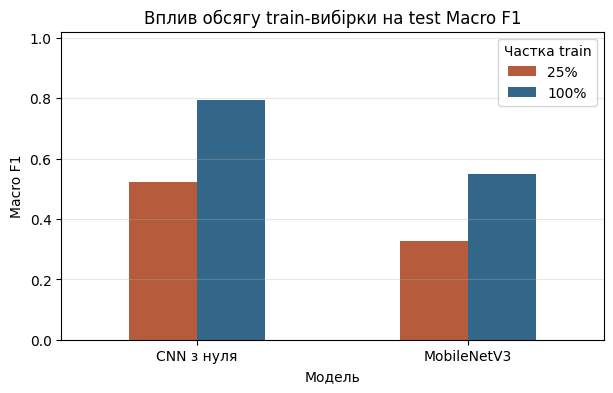

In [108]:
volume_table = volume_results.pivot(index="Модель", columns="Частка train", values="Macro F1")
ax = volume_table[["25%", "100%"]].plot(
    kind="bar", figsize=(7, 4), color=["#b65b3b", "#326789"]
)
ax.set(
    title="Вплив обсягу train-вибірки на test Macro F1",
    xlabel="Модель",
    ylabel="Macro F1",
    ylim=(0, 1.02),
)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Частка train")
plt.xticks(rotation=0)
plt.show()


CNN з нуля досягла Macro F1 0,7948, перевершивши MobileNetV3 з результатом 0,5502, але потребувала значно більше часу: близько 1481 с проти 118 с. Збільшення train-вибірки з 25% до 100% підвищило Macro F1 CNN з 0,5228 до 0,7948, а MobileNetV3 — з 0,3279 до 0,5502. Отже, додаткові дані покращили якість обох моделей.

### Висновок до розділу 2

Порівняйте test Accuracy і Macro F1, learning curves та час навчання. Зазначте, яка модель краще розпізнала 75 класів, як зміна обсягу train вплинула на результат і чи є ознаки перенавчання на графіках loss.

## 3. Рекурентні нейронні мережі для класифікації текстів



### 3.1. Датасет і класи

У `Fake.csv` текст статті зберігається в колонці `text`, а тема — у `subject`.

In [109]:
TEXT_PATH = DATA_PATH.parent / "Fake.csv"
news_df = pd.read_csv(TEXT_PATH)
topics = news_df["subject"].value_counts().head(2).index.tolist()
news = news_df.loc[news_df["subject"].isin(topics)].dropna(subset=["text", "subject"]).copy()

print(f"Усього статей у файлі: {len(news_df):,}")
print("Обрані теми:", ", ".join(topics))
display(news["subject"].value_counts().rename("Кількість текстів").to_frame())


Усього статей у файлі: 23,481
Обрані теми: News, politics


,Кількість текстів
subject,
News,9050
politics,6841


### 3.2. Очищення текстів і поділ даних

Текст переводимр в нижній регістр. Вилучаємо посилання, пунктуацію й цифри. Залишаємо тільки англійські слова довжиною від двох символів, із яких видаляються стоп-слова. 

In [110]:
def clean_text(text):
    text = re.sub(r"https?://\S+|www\.\S+", " ", str(text).lower())
    words = re.findall(r"[a-z]{2,}", text)
    return " ".join(word for word in words if word not in ENGLISH_STOP_WORDS)

news["clean_text"] = news["text"].map(clean_text)
news = news.loc[news["clean_text"].str.len() > 0].drop_duplicates(subset="clean_text").copy()

text_development, text_test = train_test_split(
    news, test_size=0.20, stratify=news["subject"], random_state=RANDOM_STATE
)
text_train, text_validation = train_test_split(
    text_development, test_size=0.20, stratify=text_development["subject"],
    random_state=RANDOM_STATE,
)

class_names = sorted(text_train["subject"].unique())
class_to_id = {name: index for index, name in enumerate(class_names)}
for frame in [text_train, text_validation, text_test]:
    frame["target"] = frame["subject"].map(class_to_id)

print(f"Train: {len(text_train):,} | Validation: {len(text_validation):,} | Test: {len(text_test):,}")


Train: 9,865 | Validation: 2,467 | Test: 3,083


### 3.3. Токенізація, словник і однакова довжина послідовностей

Розбиваємо очищений текст на слова. Словник будуємо лише за train, щоб не використовувати інформацію з validation і test. Індекс `0` зарезервовано для `<PAD>`, `1` — для `<UNK>`. Кожну статтю обрізаємо до 128 слів або доповнюємо до цієї довжини.

In [111]:
MAX_LENGTH = 128
MAX_WORDS = 30_000
PAD_INDEX = 0
UNKNOWN_INDEX = 1

for frame in [text_train, text_validation, text_test]:
    frame["tokens"] = frame["clean_text"].map(str.split)

word_counts = Counter(word for tokens in text_train["tokens"] for word in tokens)
vocabulary = {"<PAD>": PAD_INDEX, "<UNK>": UNKNOWN_INDEX}
for index, (word, _) in enumerate(word_counts.most_common(MAX_WORDS), start=2):
    vocabulary[word] = index


def encode_text(tokens):
    ids = [vocabulary.get(word, UNKNOWN_INDEX) for word in tokens[:MAX_LENGTH]]
    length = len(ids)
    ids += [PAD_INDEX] * (MAX_LENGTH - length)
    return ids, length


class NewsDataset(Dataset):
    def __init__(self, frame):
        self.sequences = [encode_text(tokens) for tokens in frame["tokens"]]
        self.labels = frame["target"].to_numpy(dtype="int64")

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        ids, length = self.sequences[index]
        return torch.tensor(ids), length, int(self.labels[index])

text_train_data = NewsDataset(text_train)
text_validation_data = NewsDataset(text_validation)
text_test_data = NewsDataset(text_test)
text_train_loader = DataLoader(text_train_data, batch_size=128, shuffle=True)
text_validation_loader = DataLoader(text_validation_data, batch_size=128)
text_test_loader = DataLoader(text_test_data, batch_size=128)

print(f"Слів у словнику: {len(vocabulary):,}")
print(f"Довжина кожної послідовності: {MAX_LENGTH} токенів")


Слів у словнику: 30,002
Довжина кожної послідовності: 128 токенів


### 3.4. GRU-модель і цикл навчання

Обидві моделі матимуть однакову архітектуру: Embedding → GRU → повнозв’язаний класифікатор. У першій Embedding починається з випадкових ваг. У другій початкові вектори слів беремо з GloVe. Після ініціалізації Embedding-шар навчається разом з рештою моделі.

In [112]:
EMBEDDING_SIZE = 50
HIDDEN_SIZE = 64
TEXT_EPOCHS = 8

class TextGRU(nn.Module):
    def __init__(self, initial_embeddings=None):
        super().__init__()
        self.embedding = nn.Embedding(
            len(vocabulary), EMBEDDING_SIZE, padding_idx=PAD_INDEX
        )
        if initial_embeddings is not None:
            with torch.no_grad():
                self.embedding.weight.copy_(initial_embeddings)
        self.gru = nn.GRU(EMBEDDING_SIZE, HIDDEN_SIZE, batch_first=True)
        self.classifier = nn.Linear(HIDDEN_SIZE, len(class_names))

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)
        outputs, _ = self.gru(embedded)
        last_positions = lengths.to(token_ids.device) - 1
        rows = torch.arange(len(token_ids), device=token_ids.device)
        final_states = outputs[rows, last_positions]
        return self.classifier(final_states)


def train_text_model(model, epochs):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.CrossEntropyLoss()
    history = {"train_loss": [], "validation_loss": [], "seconds": []}
    best_loss = float("inf")
    best_weights = None

    for epoch in range(epochs):
        start = perf_counter()
        model.train()
        train_loss_sum = 0.0
        for token_ids, lengths, labels in text_train_loader:
            token_ids, labels = token_ids.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = loss_function(model(token_ids, lengths), labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(labels)

        model.eval()
        validation_loss_sum = 0.0
        with torch.no_grad():
            for token_ids, lengths, labels in text_validation_loader:
                token_ids, labels = token_ids.to(device), labels.to(device)
                loss = loss_function(model(token_ids, lengths), labels)
                validation_loss_sum += loss.item() * len(labels)

        train_loss = train_loss_sum / len(text_train_data)
        validation_loss = validation_loss_sum / len(text_validation_data)
        history["train_loss"].append(train_loss)
        history["validation_loss"].append(validation_loss)
        history["seconds"].append(perf_counter() - start)
        print(
            f"Епоха {epoch + 1}/{epochs}: "
            f"train loss={train_loss:.4f}, validation loss={validation_loss:.4f}"
        )

        if validation_loss < best_loss:
            best_loss = validation_loss
            best_weights = {
                name: value.detach().cpu().clone()
                for name, value in model.state_dict().items()
            }

    model.load_state_dict(best_weights)
    return model, history


def predict_text(model, loader):
    model.eval()
    true_labels, predictions = [], []
    with torch.no_grad():
        for token_ids, lengths, labels in loader:
            scores = model(token_ids.to(device), lengths)
            predictions.extend(scores.argmax(dim=1).cpu().numpy())
            true_labels.extend(labels.numpy())
    return np.array(true_labels), np.array(predictions)


### 3.5. Навчання з випадковими Embedding-вагами

Спершу навчаємо GRU зі випадковою ініціалізацією embedding-векторів. Validation loss використовується для збереження найкращої епохи.

In [113]:
torch.manual_seed(RANDOM_STATE)
random_embedding_model = TextGRU()
random_embedding_model, random_embedding_history = train_text_model(
    random_embedding_model, epochs=TEXT_EPOCHS
)


Епоха 1/8: train loss=0.6711, validation loss=0.6598
Епоха 2/8: train loss=0.6209, validation loss=0.6285
Епоха 3/8: train loss=0.5420, validation loss=0.5859
Епоха 4/8: train loss=0.4725, validation loss=0.5199
Епоха 5/8: train loss=0.3869, validation loss=0.4850
Епоха 6/8: train loss=0.3160, validation loss=0.4685
Епоха 7/8: train loss=0.2524, validation loss=0.4580
Епоха 8/8: train loss=0.1996, validation loss=0.4509


### 3.6. Навчання з GloVe-векторами

Файл GloVe містить 400 000 векторів розмірності 50. Зчитуємо лише слова, які є в нашому словнику. Якщо слова немає в GloVe, для нього залишаємо випадковий вектор; `<PAD>` має нульовий вектор.

In [114]:
GLOVE_PATH = DATA_PATH.parent / "pretrained" / "glove-wiki-gigaword-50.gz"
glove_embeddings = torch.randn(len(vocabulary), EMBEDDING_SIZE) * 0.1
glove_embeddings[PAD_INDEX] = 0
matched_words = set()

with gzip.open(GLOVE_PATH, "rt", encoding="utf-8") as glove_file:
    glove_file.readline()  # Розмір словника й довжина вектора у першому рядку.
    for line in glove_file:
        word, values = line.rstrip().split(" ", 1)
        if word in vocabulary:
            vector = torch.tensor([float(value) for value in values.split()])
            glove_embeddings[vocabulary[word]] = vector
            matched_words.add(word)

coverage = len(matched_words) / max(1, len(vocabulary) - 2)
print(f"Покриття словника GloVe: {coverage:.1%} ({len(matched_words):,} слів)")

torch.manual_seed(RANDOM_STATE)
glove_model = TextGRU(initial_embeddings=glove_embeddings)
glove_model, glove_history = train_text_model(glove_model, epochs=TEXT_EPOCHS)


Покриття словника GloVe: 92.8% (27,855 слів)
Епоха 1/8: train loss=0.6491, validation loss=0.6163
Епоха 2/8: train loss=0.5223, validation loss=0.4699
Епоха 3/8: train loss=0.3941, validation loss=0.4054
Епоха 4/8: train loss=0.2736, validation loss=0.4137
Епоха 5/8: train loss=0.1903, validation loss=0.3886
Епоха 6/8: train loss=0.1079, validation loss=0.3711
Епоха 7/8: train loss=0.0594, validation loss=0.3036
Епоха 8/8: train loss=0.0313, validation loss=0.4074


### 3.7. Learning curves і порівняння результатів

Порівняємо обидва підходи на тих самих test-текстах. Learning curves показують збіжність і розрив між train та validation loss. У таблиці наведено якість, найкращу епоху та час навчання.

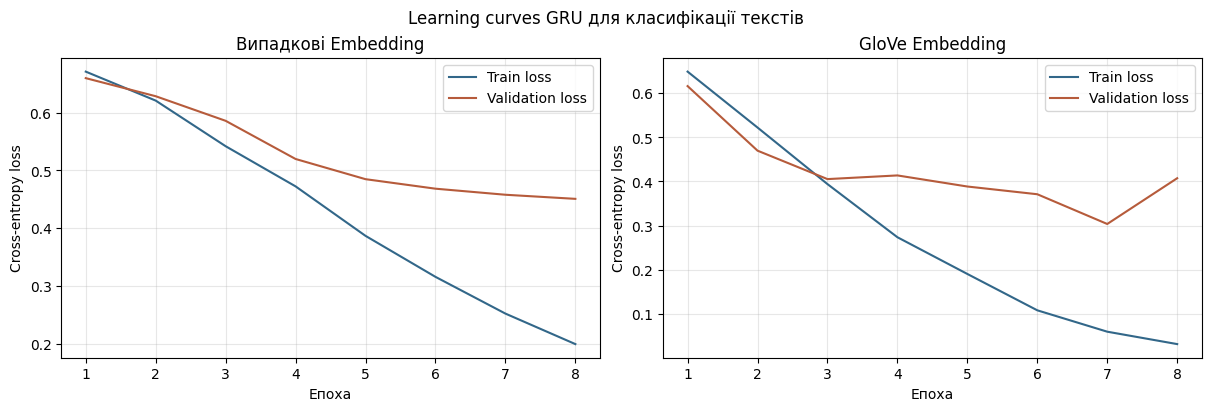

,Модель,Accuracy,Macro F1,Найкраща епоха,Секунд на епоху,"Час навчання, с"
0,GRU: випадкові Embedding,0.8394,0.8332,8,9.5264,76.2115
1,GRU: GloVe,0.8956,0.8915,7,9.4805,75.8444


In [115]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, name, history in [
    (axes[0], "Випадкові Embedding", random_embedding_history),
    (axes[1], "GloVe Embedding", glove_history),
]:
    epochs = range(1, len(history["train_loss"]) + 1)
    ax.plot(epochs, history["train_loss"], label="Train loss", color="#326789")
    ax.plot(epochs, history["validation_loss"], label="Validation loss", color="#b65b3b")
    ax.set(title=name, xlabel="Епоха", ylabel="Cross-entropy loss")
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Learning curves GRU для класифікації текстів")
plt.show()

random_true, random_predictions = predict_text(random_embedding_model, text_test_loader)
glove_true, glove_predictions = predict_text(glove_model, text_test_loader)
text_results = pd.DataFrame([
    {
        "Модель": "GRU: випадкові Embedding",
        "Accuracy": accuracy_score(random_true, random_predictions),
        "Macro F1": f1_score(random_true, random_predictions, average="macro"),
        "Найкраща епоха": int(np.argmin(random_embedding_history["validation_loss"])) + 1,
        "Секунд на епоху": np.mean(random_embedding_history["seconds"]),
        "Час навчання, с": sum(random_embedding_history["seconds"]),
    },
    {
        "Модель": "GRU: GloVe",
        "Accuracy": accuracy_score(glove_true, glove_predictions),
        "Macro F1": f1_score(glove_true, glove_predictions, average="macro"),
        "Найкраща епоха": int(np.argmin(glove_history["validation_loss"])) + 1,
        "Секунд на епоху": np.mean(glove_history["seconds"]),
        "Час навчання, с": sum(glove_history["seconds"]),
    },
])
display(text_results.round(4))


### 3.8. Детальні метрики для кожної моделі

Нижче наведено загальні та покласові метрики на test для обох GRU-моделей.

Загальні метрики на test:


,Модель,Accuracy,Macro F1
0,GRU: випадкові Embedding,0.839,0.833
1,GRU: GloVe,0.896,0.891


Метрики для кожної теми:


,Модель,Категорія,Precision,Recall,F1,Кількість тестових текстів
0,GRU: випадкові Embedding,News,0.851,0.880,0.866,1810
1,GRU: випадкові Embedding,politics,0.821,0.782,0.801,1273
2,GRU: GloVe,News,0.897,0.928,0.913,1810
3,GRU: GloVe,politics,0.893,0.849,0.870,1273


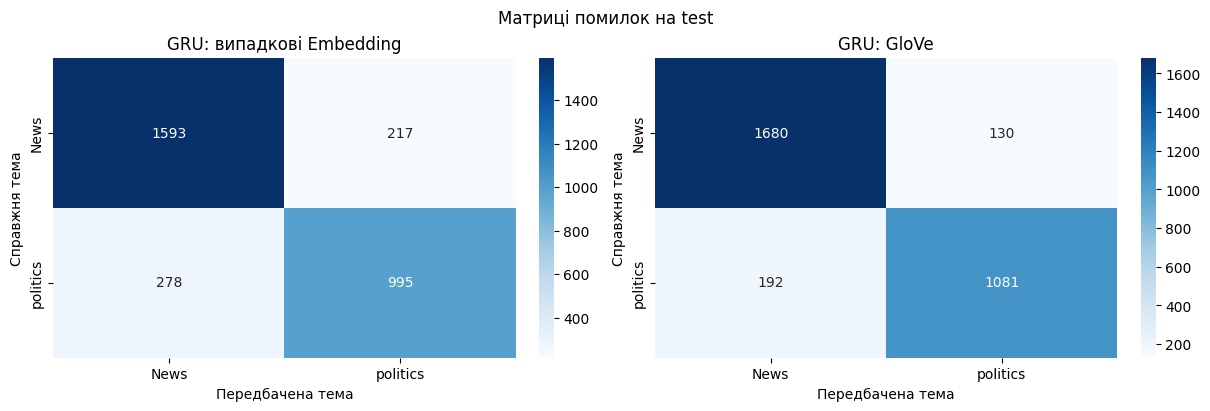

In [116]:
model_predictions = [
    ("GRU: випадкові Embedding", random_true, random_predictions),
    ("GRU: GloVe", glove_true, glove_predictions),
]

overall_metrics = pd.DataFrame([
    {
        "Модель": name,
        "Accuracy": accuracy_score(true, predicted),
        "Macro F1": f1_score(true, predicted, average="macro"),
    }
    for name, true, predicted in model_predictions
])
print("Загальні метрики на test:")
display(overall_metrics.round(3))

class_metric_tables = []
for name, true, predicted in model_predictions:
    precision, recall, f1, support = precision_recall_fscore_support(
        true,
        predicted,
        labels=list(range(len(class_names))),
        zero_division=0,
    )
    class_metrics = pd.DataFrame({
        "Категорія": class_names,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Кількість тестових текстів": support,
    })
    class_metrics.insert(0, "Модель", name)
    class_metric_tables.append(class_metrics)

print("Метрики для кожної теми:")
display(pd.concat(class_metric_tables, ignore_index=True).round(3))

fig, axes = plt.subplots(1, len(model_predictions), figsize=(12, 4), layout="constrained")
for ax, (name, true, predicted) in zip(axes, model_predictions):
    matrix = confusion_matrix(true, predicted, labels=list(range(len(class_names))))
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
    )
    ax.set(title=name, xlabel="Передбачена тема", ylabel="Справжня тема")
fig.suptitle("Матриці помилок на test")
plt.show()


GloVe підвищило test Macro F1 GRU з 0,8332 до 0,8915 за майже однакового часу навчання. На восьмій епосі GloVe validation loss зріс із 0,3036 до 0,4074 при подальшому зниженні train loss, що вказує на перенавчання. Для фінального оцінювання використано ваги сьомої епохи.